# 🗺️ Task 1a — Join Loss & Zone Mapping
**Owner:** Person A  
**Branch:** `phase1/data-joins`  
**Goal:** اكتشاف الصفوف التي تفقد قيمها (NaN) عند عمل Join بين `trips` و `zones`، وإصلاحها بالاعتماد على `legacy_name` الموثقة في `zones.csv`.

---

## Cell 1 (Imports & Paths)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json

# Paths (relative to notebooks/ folder)
PACK = "../data/raw/CairoGo_pack_v17/"

TRIPS_PATH   = PACK + "trips.csv"
ZONES_PATH   = PACK + "zones.csv"
CUST_PATH    = PACK + "customers.csv"
DRIVERS_PATH = PACK + "drivers.csv"

print("Imports done")

Imports done


## Cell 2 (Load Data)

In [3]:
trips   = pd.read_csv(TRIPS_PATH)
zones   = pd.read_csv(ZONES_PATH)
cust    = pd.read_csv(CUST_PATH)
drivers = pd.read_csv(DRIVERS_PATH)

print(f"trips   : {trips.shape}")
print(f"zones   : {zones.shape}")
print(f"cust    : {cust.shape}")
print(f"drivers : {drivers.shape}")

print("\ntrips columns:", trips.columns.tolist())
print("zones columns:", zones.columns.tolist())

trips   : (28244, 18)
zones   : (24, 5)
cust    : (6000, 5)
drivers : (1500, 6)

trips columns: ['trip_id', 'customer_id', 'driver_id', 'request_ts', 'pickup_zone', 'dropoff_zone', 'distance_km', 'surge_multiplier', 'est_fare', 'eta_estimate_min', 'weather', 'payment_method', 'service_level', 'request_failed', 'actual_trip_time_min', 'cancel_reason', 'driver_arrival_min', 'support_ticket_flag']
zones columns: ['zone_id', 'zone_name', 'legacy_name', 'zone_type', 'has_metro']


In [4]:
# to display all zones
print("zones.csv")
print(zones.to_string())

zones.csv
   zone_id           zone_name    legacy_name zone_type  has_metro
0      Z01            Downtown       Downtown  downtown          1
1      Z02             Zamalek        Zamalek  downtown          1
2      Z03         Garden City    Garden City  downtown          1
3      Z04              Abdeen         Abdeen  downtown          1
4      Z05              Shubra         Shubra  downtown          1
5      Z06              Ramses         Ramses  downtown          1
6      Z07               Maadi          Maadi   midtown          1
7      Z08           Nasr City      Nasr City   midtown          1
8      Z09          Heliopolis     Heliopolis   midtown          1
9      Z10         Mohandessin    Mohandessin   midtown          0
10     Z11      Dokki District          Dokki   midtown          0
11     Z12              Agouza         Agouza   midtown          0
12     Z13  New Cairo District      New Cairo  new_city          0
13     Z14         6th October    6th October  new_c

## Cell 3 (Check for Unmatched Zones)

In [8]:
# zones.csv
valid_zone_names = set(zones["zone_name"])

# trips (pickup_zone)
trips_pickup_zones = set(trips["pickup_zone"].dropna())

# Unmatched zones (in trips but not in zones)
unmatched_zones = trips_pickup_zones - valid_zone_names

print("Valid zone names (from zones.csv):", sorted(valid_zone_names))
print("\nZones in trips pickup_zone:", sorted(trips_pickup_zones))
print("\nUNMATCHED zone names:", sorted(unmatched_zones))
print("Count of unmatched names:", len(unmatched_zones))

Valid zone names (from zones.csv): ['6th October', 'Abdeen', 'Agouza', 'Badr City District', 'Cairo Airport', 'Dokki District', 'Downtown', 'Garden City', 'Heliopolis', 'Helwan', 'Khanka', 'Maadi', 'Madinaty', 'Mohandessin', 'Nasr City', 'New Cairo District', 'Obour', 'Qalyub', 'Ramses', 'Sheikh Zayed', 'Shorouk', 'Shubra', 'Tora', 'Zamalek']

Zones in trips pickup_zone: ['6th October', 'Abdeen', 'Agouza', 'Badr City', 'Cairo Airport', 'Dokki', 'Downtown', 'Garden City', 'Heliopolis', 'Helwan', 'Khanka', 'Maadi', 'Madinaty', 'Mohandessin', 'Nasr City', 'New Cairo', 'Obour', 'Qalyub', 'Ramses', 'Sheikh Zayed', 'Shorouk', 'Shubra', 'Tora', 'Zamalek']

UNMATCHED zone names: ['Badr City', 'Dokki', 'New Cairo']
Count of unmatched names: 3


In [11]:
# number of unmatched rows
unmatched_rows_mask = trips["pickup_zone"].isin(unmatched_zones)
n_unmatched         = unmatched_rows_mask.sum()
total_rows          = len(trips)
unmatched_fraction  = round(n_unmatched / total_rows, 4)

print(f"Rows with unmatched pickup_zone: {n_unmatched} out of {total_rows}")
print(f"Fraction (results.json): {unmatched_fraction}")

Rows with unmatched pickup_zone: 3243 out of 28244
Fraction (results.json): 0.1148


In [ ]:
# Failure Rate
fail_unmatched = trips[unmatched_rows_mask]["request_failed"].mean()
fail_matched   = trips[~unmatched_rows_mask]["request_failed"].mean()

print(f"Failure rate (UNMATCHED rows): {fail_unmatched:.3f}")
print(f"Failure rate (MATCHED rows): {fail_matched:.3f}")
print("\Some of unmatched rows:")
print(trips[unmatched_rows_mask][["trip_id", "pickup_zone", "request_failed"]].head(10).to_string())

Failure rate (UNMATCHED rows): 0.192
Failure rate (MATCHED rows): 0.176
\Some of unmatched rows:
     trip_id pickup_zone  request_failed
4     100005       Dokki               0
7     100008       Dokki               1
15    100016   Badr City               1
16    100017   Badr City               1
25    100026   New Cairo               0
35    100036   Badr City               0
72    100073   Badr City               0
86    100087   New Cairo               0
90    100091       Dokki               0
100   100101       Dokki               0


## Cell 4 (Fix using legacy_name)

In [14]:
# from legacy_name to zone_name
legacy_to_current = zones.set_index("legacy_name")["zone_name"].to_dict()

print("Legacy to Current mapping:")
for k, v in legacy_to_current.items():
    if k != v:
        print(f" '{k}' to '{v}'")

Legacy to Current mapping:
 'Dokki' to 'Dokki District'
 'New Cairo' to 'New Cairo District'
 'Badr City' to 'Badr City District'


In [15]:
# apply on pickup_zone and dropoff_zone
trips["pickup_zone"]  = trips["pickup_zone"].replace(legacy_to_current)
trips["dropoff_zone"] = trips["dropoff_zone"].replace(legacy_to_current)

# ensure that there is no unmatched zones after fixing)
still_unmatched = trips[~trips["pickup_zone"].isin(valid_zone_names)]["pickup_zone"].unique()
print("Still unmatched after fix:", list(still_unmatched))
print("Fix verified: All pickup zones successfully mapped!")

Still unmatched after fix: []
Fix verified: All pickup zones successfully mapped!


## Cell 5 (Full Join)

In [16]:
# 1. Join with zones
trips_merged = trips.merge(
    zones[["zone_name", "zone_type", "has_metro"]].rename(columns={"zone_name": "pickup_zone"}),
    on="pickup_zone",
    how="left"
)

# 2. Join with customers 
cust_renamed = cust.rename(columns={"home_zone": "customer_home_zone"})
trips_merged = trips_merged.merge(cust_renamed, on="customer_id", how="left")

# 3. Join with drivers
drivers_renamed = drivers.rename(columns={"home_zone": "driver_home_zone"})
trips_merged = trips_merged.merge(drivers_renamed, on="driver_id", how="left")

print("Final merged shape:", trips_merged.shape)
print("Missing zone_type after join:", trips_merged["zone_type"].isna().sum())
print("\nFirst 3 rows:")
print(trips_merged.head(3).to_string())

Final merged shape: (28244, 29)
Missing zone_type after join: 0

First 3 rows:
   trip_id  customer_id  driver_id           request_ts  pickup_zone dropoff_zone  distance_km  surge_multiplier  est_fare  eta_estimate_min weather payment_method service_level  request_failed  actual_trip_time_min    cancel_reason  driver_arrival_min  support_ticket_flag zone_type  has_metro signup_date  channel customer_home_zone loyalty_tier   join_date vehicle_type  experience_months driver_home_zone  rating_avg
0   100001        20507       6168  2026-05-01 00:01:03   Heliopolis       Agouza         5.75               1.0      59.2               9.0   clear         wallet       comfort               0                  22.6              NaN                 9.9                    0   midtown          1  2025-11-13  organic         Heliopolis         gold  2026-04-04        sedan                 34       Heliopolis        4.43
1   100002        23628       6267  2026-05-01 00:07:39  Mohandessin  Garden Ci

## Cell 6 (Visualization)

C:\Users\maria\AppData\Local\Temp\ipykernel_28104\1384075454.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=zone_counts.index, y=zone_counts.values, palette="Reds_r", edgecolor="black")


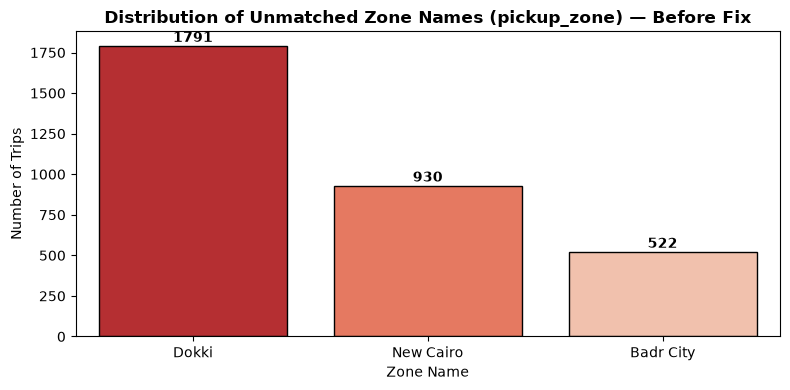

Saved to reports/figures/01_unmatched_zones.png


In [ ]:
# Bar chart for unmatched zones (before fixing)
original_trips = pd.read_csv(TRIPS_PATH)
unmatched_mask_orig = original_trips["pickup_zone"].isin(unmatched_zones)
zone_counts = original_trips[unmatched_mask_orig]["pickup_zone"].value_counts()

plt.figure(figsize=(8, 4))
sns.barplot(x=zone_counts.index, y=zone_counts.values, palette="Reds_r", edgecolor="black")
plt.title("Distribution of Unmatched Zone Names (pickup_zone) Before Fix", fontsize=12, fontweight="bold")
plt.xlabel("Zone Name", fontsize=10)
plt.ylabel("Number of Trips", fontsize=10)
for i, v in enumerate(zone_counts.values):
    plt.text(i, v + 25, str(v), ha="center", fontweight="bold")
plt.tight_layout()
plt.savefig("../reports/figures/01_unmatched_zones.png", dpi=150)
plt.show()
print("Saved to reports/figures/01_unmatched_zones.png")

## Cell 7 (results.json)

In [18]:
result_join = {
    "unmatched_before" : unmatched_fraction,
    "unmatched_zones"  : sorted(list(unmatched_zones)),
    "fix"              : "Replaced legacy zone names in pickup_zone and dropoff_zone using legacy_name to zone_name mapping from zones.csv"
}

print("JOIN block to copy to results.json")
print(json.dumps(result_join, indent=2))

JOIN block to copy to results.json
{
  "unmatched_before": 0.1148,
  "unmatched_zones": [
    "Badr City",
    "Dokki",
    "New Cairo"
  ],
  "fix": "Replaced legacy zone names in pickup_zone and dropoff_zone using legacy_name to zone_name mapping from zones.csv"
}


## Cell 8 (Save the Cleaned Dataset)

In [19]:
trips_merged.to_csv("../data/processed/trips_cleaned.csv", index=False)
print("Saved: data/processed/trips_cleaned.csv")
print("Shape:", trips_merged.shape)
print("Columns:", trips_merged.columns.tolist())

Saved: data/processed/trips_cleaned.csv
Shape: (28244, 29)
Columns: ['trip_id', 'customer_id', 'driver_id', 'request_ts', 'pickup_zone', 'dropoff_zone', 'distance_km', 'surge_multiplier', 'est_fare', 'eta_estimate_min', 'weather', 'payment_method', 'service_level', 'request_failed', 'actual_trip_time_min', 'cancel_reason', 'driver_arrival_min', 'support_ticket_flag', 'zone_type', 'has_metro', 'signup_date', 'channel', 'customer_home_zone', 'loyalty_tier', 'join_date', 'vehicle_type', 'experience_months', 'driver_home_zone', 'rating_avg']


---
## Summary of Task 1a Findings

| Item | Value |
|---|---|
| **Unmatched zone names** | `['Badr City', 'Dokki', 'New Cairo']` (Total: 3 zones) |
| **Rows affected** | 3,243 out of 28,244 trips |
| **Fraction (`join.unmatched_before`)** | **0.1148** (11.48% of total dataset) |
| **Failure rate (Unmatched vs Matched)** | 19.2% failure in unmatched vs 17.6% in matched (shows non-random distribution) |
| **Fix applied** | Mapped legacy names to current official zone names using `legacy_name → zone_name` from `zones.csv` |
| **Mapping details** | `Dokki` → `Dokki District`, `New Cairo` → `New Cairo District`, `Badr City` → `Badr City District` |
| **Rows still unmatched after fix** | **0** (100% match rate achieved) |
| **Post-join verification** | `trips_merged` shape is (28,244, 29) with 0 missing `zone_type` values |